# Root Finding Lab
Mohammad Rohaan · CS2008 Numerical Computing · Fall 2025

This study compares five scalar solvers on seven analytic equations. Run from top to bottom to recompute the tables and traces. The gallery and CSV files in the repository are saved snapshots from a separate run.

[Assignment brief](../docs/assignment_brief.pdf) · [Method notes](../docs/method_notes.md)

In [1]:
from pathlib import Path
import sys

root = Path.cwd()
if root.name == "notebooks":
    root = root.parent
sys.path.insert(0, str(root))

from rootlab.experiments import (
    bracketing_rows, experiment_rows, convergence_rows, benchmark_rows, traces,
)
from rootlab.problems import PROBLEMS
from IPython.display import Markdown, display
import matplotlib.pyplot as plt

def show(records, *fields):
    def fmt(value):
        if value is None:
            return "—"
        return f"{value:.8g}" if isinstance(value, float) else str(value).replace("|", "&#124;")
    head = "| " + " | ".join(fields) + " |"
    rule = "| " + " | ".join(["---"] * len(fields)) + " |"
    rows = ["| " + " | ".join(fmt(row[field]) for field in fields) + " |" for row in records]
    display(Markdown("\n".join([head, rule, *rows])))

## Q1–Q2 · Sign checks and bisection
The signed endpoint values justify the seven sign-changing brackets by continuity. The even-multiplicity root at x = 1 touches the axis; its interval fails the bracketing test.

In [2]:
show(bracketing_rows(), "case", "equation", "a", "b", "fa", "fb", "sign_change")
runs = list(experiment_rows())
show((r for r in runs if r["method"] == "Bisection"),
     "case", "root", "iterations", "residual", "status")

| case | equation | a | b | fa | fb | sign_change |
| --- | --- | --- | --- | --- | --- | --- |
| f1 | x³ + x − 3 | 0 | 4 | -3 | 65 | True |
| f2 | cos(x) − x | 0 | 1 | 1 | -0.45969769 | True |
| f3 | x exp(−x) − 0.1 | 0 | 2 | -0.1 | 0.17067057 | True |
| f4 | x³ − 2x² − 5 | 2 | 4 | -5 | 27 | True |
| f5-left | (x − 1)²(x + 2) | -3 | 0 | -16 | 2 | True |
| f5-right | (x − 1)²(x + 2) | 0 | 3 | 2 | 20 | False |
| f6 | ∛x | -0.001 | 0.001 | -0.1 | 0.1 | True |
| f7 | x + sin(x) − 1 | 0 | 1 | -1 | 0.84147098 | True |

| case | root | iterations | residual | status |
| --- | --- | --- | --- | --- |
| f1 | 1.2134117 | 30 | 1.8762281e-10 | residual |
| f2 | 0.73908514 | 24 | 7.7470247e-09 | residual |
| f3 | 0.11183256 | 25 | 3.9891437e-11 | residual |
| f4 | 2.6906474 | 30 | 5.9915113e-09 | residual |
| f5-left | -2 | 30 | 8.3819032e-09 | residual |
| f5-right | — | — | — | endpoints must have opposite signs |
| f6 | 0 | 1 | 0 | residual |
| f7 | 0.51097343 | 27 | 3.3352927e-09 | residual |

## Q3 · Fixed-point maps
The best map for each of f1–f3 is locally contractive at the assigned root. The competing maps exhibit overflow, a domain exit, or attraction away from the intended root. The f5-right map uses the known repeated factor to illustrate linear convergence.

In [3]:
show((r for r in runs if r["method"] == "Fixed-point"),
     "case", "seed", "root", "iterations", "residual", "in_interval", "status")

| case | seed | root | iterations | residual | in_interval | status |
| --- | --- | --- | --- | --- | --- | --- |
| f1 | ∛(3 − x) at 1.0; &#124;g′&#124;=0.226 | 1.2134117 | 13 | 4.6000661e-09 | True | residual |
| f1 | 3 − x³ at 1.0; &#124;g′&#124;=4.417 | -7.8462762e+56 | 6 | 4.8304853e+170 | False | (34, 'Result too large') |
| f2 | cos(x) at 0.5; &#124;g′&#124;=0.674 | 0.73908513 | 44 | 9.9893604e-09 | True | residual |
| f2 | arccos(x) at 0.5; &#124;g′&#124;=1.485 | 1.0471976 | 1 | 0.54719755 | False | expected a number in range from -1 up to 1, got 1.0471975511965979 |
| f3 | 0.1 exp(x) at 0.5; &#124;g′&#124;=0.112 | 0.11183257 | 8 | 9.4964927e-09 | True | residual |
| f3 | x + f3(x) at 0.5; &#124;g′&#124;=1.794 | 3.5771515 | 200 | 3.7719888e-08 | False | iteration-limit |
| f5-left | x − f5(x)/10 at -2.4; &#124;g′&#124;=0.100 | -2 | 9 | 8.1396749e-09 | True | residual |
| f5-right | 1 + 0.5(x − 1) at 1.5; &#124;g′&#124;=0.500 | 1.0000305 | 14 | 2.7939961e-09 | True | residual |

## Q4–Q5 · Open solvers and safeguarded Newton
Three Newton seeds and three Secant pairs probe sensitivity on each interval. A flat initial derivative stops Newton on f3. The hybrid accepts Newton proposals only when they satisfy the bracket and improvement guards; every accepted point updates the interval.

In [4]:
for p in PROBLEMS:
    display(Markdown(f"**{p.key}**"))
    show((r for r in runs if r["case"] == p.key and r["method"] in ("Newton", "Secant", "Hybrid")),
         "method", "seed", "root", "iterations", "residual", "in_interval", "status")

**f1**

| method | seed | root | iterations | residual | in_interval | status |
| --- | --- | --- | --- | --- | --- | --- |
| Hybrid | (0, 4) | 1.2134117 | 18 | 1.0537349e-11 | True | residual |
| Newton | 1.0 | 1.2134117 | 4 | 9.5834451e-13 | True | residual |
| Newton | 2.0 | 1.2134117 | 5 | 5.8664185e-13 | True | residual |
| Newton | 3.0 | 1.2134117 | 6 | 1.5933921e-12 | True | residual |
| Secant | (0, 4) | 1.2134117 | 11 | 4.1574832e-10 | True | residual |
| Secant | (1.0, 2.0) | 1.2134117 | 6 | 1.5405455e-11 | True | residual |
| Secant | (2.0, 3.0) | 1.2134117 | 7 | 2.6864013e-09 | True | residual |

**f2**

| method | seed | root | iterations | residual | in_interval | status |
| --- | --- | --- | --- | --- | --- | --- |
| Hybrid | (0, 1) | 0.73908513 | 15 | 3.743672e-12 | True | residual |
| Newton | 0.25 | 0.73908513 | 4 | 9.8920871e-14 | True | residual |
| Newton | 0.5 | 0.73908513 | 3 | 1.1809779e-09 | True | residual |
| Newton | 0.75 | 0.73908513 | 2 | 2.4991031e-10 | True | residual |
| Secant | (0, 1) | 0.73908513 | 5 | 2.6678659e-13 | True | residual |
| Secant | (0.25, 0.5) | 0.73908513 | 5 | 5.6954441e-14 | True | residual |
| Secant | (0.5, 0.75) | 0.73908513 | 3 | 3.7243031e-10 | True | residual |

**f3**

| method | seed | root | iterations | residual | in_interval | status |
| --- | --- | --- | --- | --- | --- | --- |
| Hybrid | (0, 2) | 0.11183255 | 13 | 5.8445173e-09 | True | residual |
| Newton | 0.5 | 0.11183256 | 5 | 2.7537e-10 | True | residual |
| Newton | 1.0 | 1 | 0 | 0.26787944 | True | unusable derivative |
| Newton | 1.5 | 3.577152 | 3 | 1.0394093e-09 | False | residual |
| Secant | (0, 2) | 3.5771521 | 8 | 5.1562976e-11 | False | residual |
| Secant | (0.5, 1.0) | 0.11183256 | 14 | 6.4068598e-11 | True | residual |
| Secant | (1.0, 1.5) | 3.5771521 | 8 | 8.26611e-12 | False | residual |

... (6 outputs left out)

**f6**

| method | seed | root | iterations | residual | in_interval | status |
| --- | --- | --- | --- | --- | --- | --- |
| Hybrid | (-0.001, 0.001) | 0 | 1 | 0 | True | residual |
| Newton | -0.0005 | 3.0223145e+20 | 79 | 6710886.4 | False | unusable derivative |
| Newton | 0.0 | 0 | 0 | 0 | True | residual |
| Newton | 0.0005 | -3.0223145e+20 | 79 | 6710886.4 | False | unusable derivative |
| Secant | (-0.001, 0.001) | 0 | 1 | 0 | True | residual |
| Secant | (-0.0005, 0.0) | 0 | 0 | 0 | True | residual |
| Secant | (0.0, 0.0005) | 0 | 0 | 0 | True | residual |

**f7**

| method | seed | root | iterations | residual | in_interval | status |
| --- | --- | --- | --- | --- | --- | --- |
| Hybrid | (0, 1) | 0.51097343 | 15 | 5.0508708e-11 | True | residual |
| Newton | 0.25 | 0.51097343 | 3 | 4.3527404e-12 | True | residual |
| Newton | 0.5 | 0.51097343 | 2 | 5.8564487e-11 | True | residual |
| Newton | 0.75 | 0.51097343 | 3 | 4.4370729e-11 | True | residual |
| Secant | (0, 1) | 0.51097343 | 4 | 8.6602947e-09 | True | residual |
| Secant | (0.25, 0.5) | 0.51097343 | 3 | 3.1797232e-11 | True | residual |
| Secant | (0.5, 0.75) | 0.51097343 | 3 | 1.4467623e-09 | True | residual |

## Q6 · Convergence and root error
Zero and tiny values are placed at 10⁻¹⁷ for logarithmic plotting. Local order estimates are descriptive. Newton approaches order two on the simple roots and order one at the repeated root. Bracket widths give a more consistent bisection convergence measure than point errors.

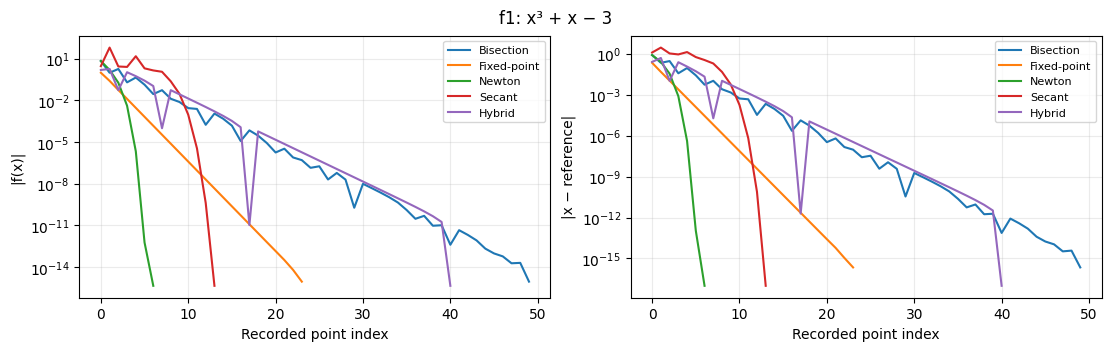

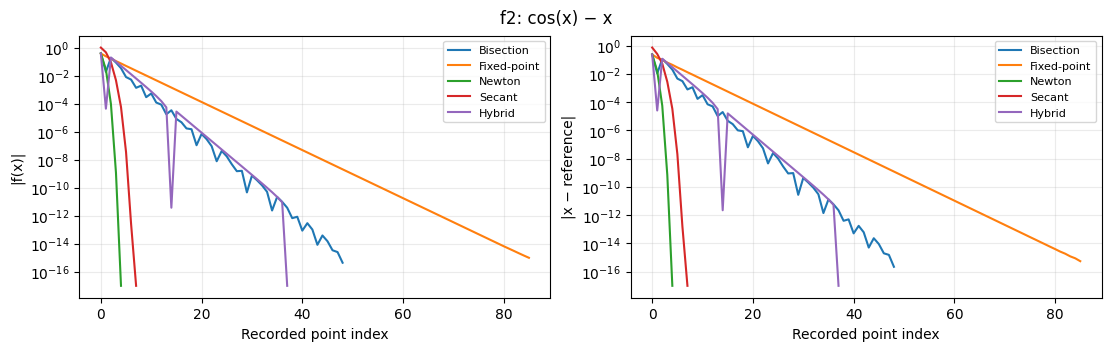

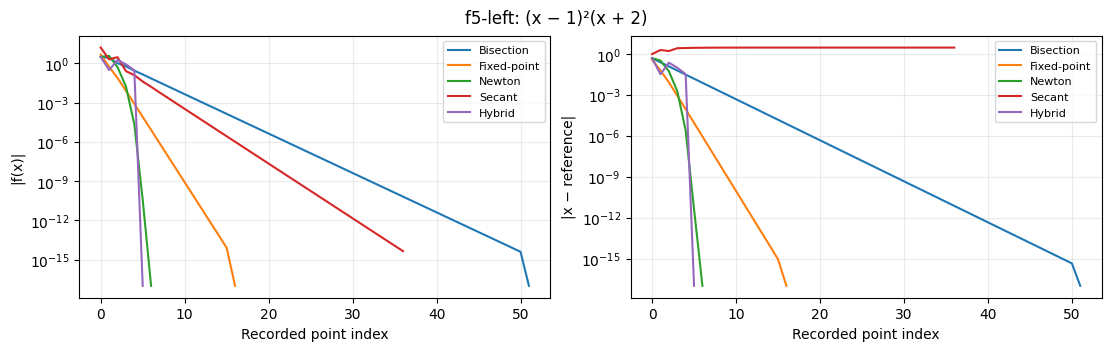

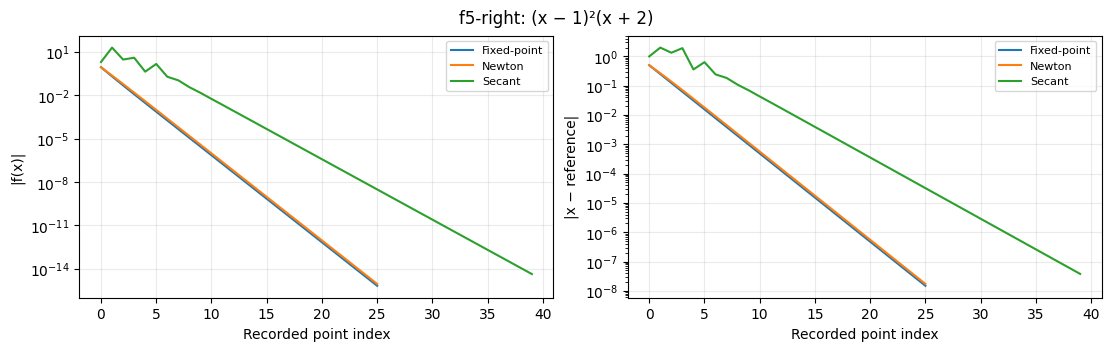

| case | method | samples | order | status |
| --- | --- | --- | --- | --- |
| f1 | Bisection | 50 | 0.59207443 | residual |
| f1 | Fixed-point | 24 | 0.99788853 | residual |
| f1 | Newton | 7 | 1.9996727 | residual |
| f1 | Secant | 14 | 1.6191035 | residual |
| f1 | Hybrid | 41 | 1.1895613 | residual |
| f2 | Bisection | 49 | 1.7604745 | residual |
| f2 | Fixed-point | 86 | 1.0175903 | residual |
| f2 | Newton | 5 | 1.9970095 | residual |
| f2 | Secant | 8 | 1.5952923 | residual |
| f2 | Hybrid | 38 | 1.1347594 | residual |
| f5-left | Bisection | 52 | 1 | residual |
| f5-left | Fixed-point | 17 | 1.0003093 | residual |
| f5-left | Newton | 7 | 1.9997087 | residual |
| f5-left | Secant | 37 | — | unusable secant slope |
| f5-left | Hybrid | 6 | 1.2966069 | residual |
| f5-right | Fixed-point | 26 | 1 | residual |
| f5-right | Newton | 26 | 1 | residual |
| f5-right | Secant | 40 | 1 | unusable secant slope |

In [5]:
for p in (PROBLEMS[0], PROBLEMS[1], PROBLEMS[4], PROBLEMS[5]):
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), layout="constrained")
    for method, result in traces(p):
        axes[0].semilogy([max(abs(s.fx), 1e-17) for s in result.steps], label=method)
        axes[1].semilogy([max(abs(s.x - p.reference), 1e-17) for s in result.steps], label=method)
    for ax, label in zip(axes, ("|f(x)|", "|x − reference|")):
        ax.set(xlabel="Recorded point index", ylabel=label)
        ax.grid(alpha=.25)
        ax.legend(fontsize=8)
    fig.suptitle(f"{p.key}: {p.equation}")
    plt.show()

show(convergence_rows(), "case", "method", "samples", "order", "status")

## Q7 · Accuracy versus time
The median covers seven batches of 200 solves with the residual target set to 10⁻¹⁰. A missing bar means the target was missed. Check the reported root along with residual: f3 Secant reaches the larger root, outside [0, 2].

| case | method | root | iterations | residual | status | median_us |
| --- | --- | --- | --- | --- | --- | --- |
| f1 | Bisection | 1.2134117 | 37 | 2.9964475e-11 | residual | 166.885 |
| f1 | Fixed-point | 1.2134117 | 16 | 5.3376414e-11 | residual | 56.4595 |
| f1 | Newton | 1.2134117 | 5 | 5.8664185e-13 | residual | 30.428 |
| f1 | Secant | 1.2134117 | 12 | 4.4408921e-16 | residual | 58.89 |
| f1 | Hybrid | 1.2134117 | 18 | 1.0537349e-11 | residual | 106.2475 |
| f2 | Bisection | 0.73908513 | 30 | 4.6338711e-11 | residual | 107.2875 |
| f2 | Fixed-point | 0.73908513 | 56 | 8.7187702e-11 | residual | 179.106 |
| f2 | Newton | 0.73908513 | 4 | 0 | residual | 11.9775 |
| f2 | Secant | 0.73908513 | 5 | 2.6678659e-13 | residual | 27.9005 |
| f2 | Hybrid | 0.73908513 | 15 | 3.743672e-12 | residual | 74.1685 |
| f3 | Bisection | 0.11183256 | 25 | 3.9891437e-11 | residual | 95.098 |
| f3 | Fixed-point | 0.11183256 | 11 | 1.3282139e-11 | residual | 41.6535 |
| f3 | Newton | 1 | 0 | 0.26787944 | unusable derivative | — |
| f3 | Secant | 3.5771521 | 8 | 5.1562976e-11 | residual | 40.97 |
| f3 | Hybrid | 0.11183256 | 28 | 1.3877788e-17 | residual | 132.337 |

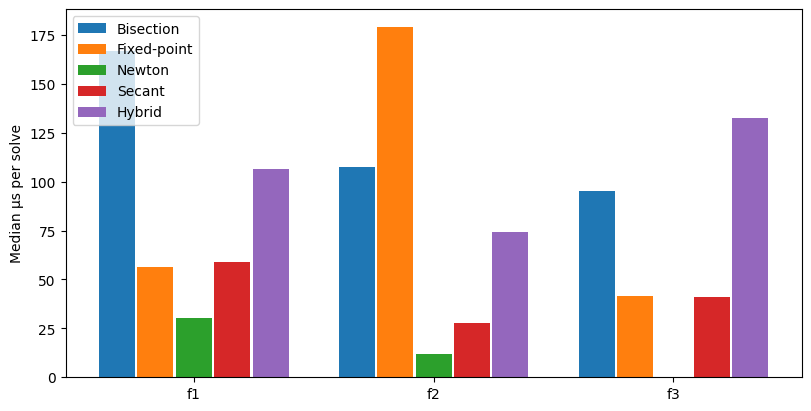

In [6]:
timing = list(benchmark_rows())
show(timing, "case", "method", "root", "iterations", "residual", "status", "median_us")
fig, ax = plt.subplots(figsize=(8, 4), layout="constrained")
methods = list(dict.fromkeys(r["method"] for r in timing))
for i, method in enumerate(methods):
    rows = [r for r in timing if r["method"] == method]
    positions = [j + (i-2)*.16 for j in range(3)]
    ax.bar(positions, [r["median_us"] or float("nan") for r in rows], .15, label=method)
ax.set(xticks=range(3), xticklabels=["f1", "f2", "f3"], ylabel="Median µs per solve")
ax.legend()
plt.show()

## Q8 · Robustness
Use safeguarded Newton when the equation is continuous and a sign-changing interval is available. Prefer bisection when the derivative is unavailable and bracket guarantees matter. Newton can struggle near a flat derivative or with a poor seed. Fixed-point iteration needs a suitable map and starting region. A small residual can coexist with a large position error near a repeated root, so inspect the bracket width, the reference error when available, and the exit reason.